## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [ ]:
df = pd.read_csv('./data/iabp.csv')
## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


In [ ]:
df

## 1.1

The point estimate of the ATE is -0.01. There is a slightly higher chance of survival among the group of people that get the intra aortic balloon pump. However, there is not enough of a difference in survival chance for me to deem the pump worth the hassle. I would rather not get the pump. 

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [15]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ate.append(ate_t) # Save new value

for t in range(R):
    df_at = df_a.sample(frac=1.0, replace=True)

    oat = df_at['Survived'].mean()  
    
    outcome_a.append(oat) 

for t in range(R):
    df_bt = df_b.sample(frac=1.0, replace=True)

    obt = df_bt['Survived'].mean()   

    outcome_b.append(obt)

#print(outcome_a)
#print(outcome_b)
#print(ate)


**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

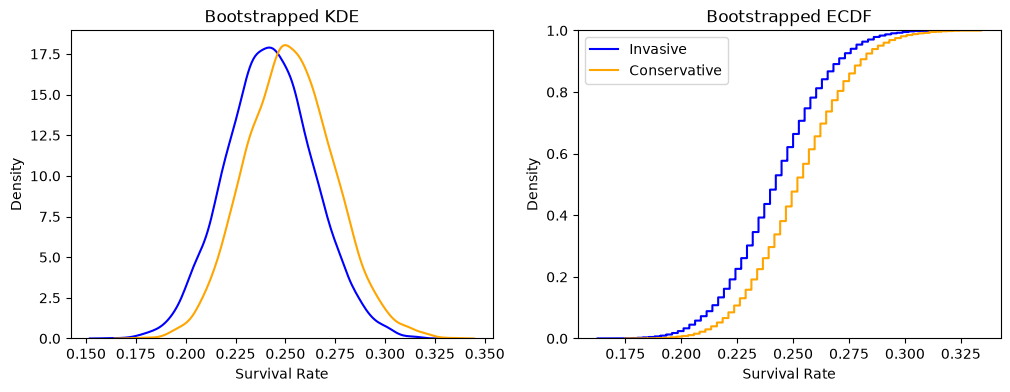

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

## 1.3

Between the two groups, the invasive group consistently has a higher survival rate throughout every density.

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

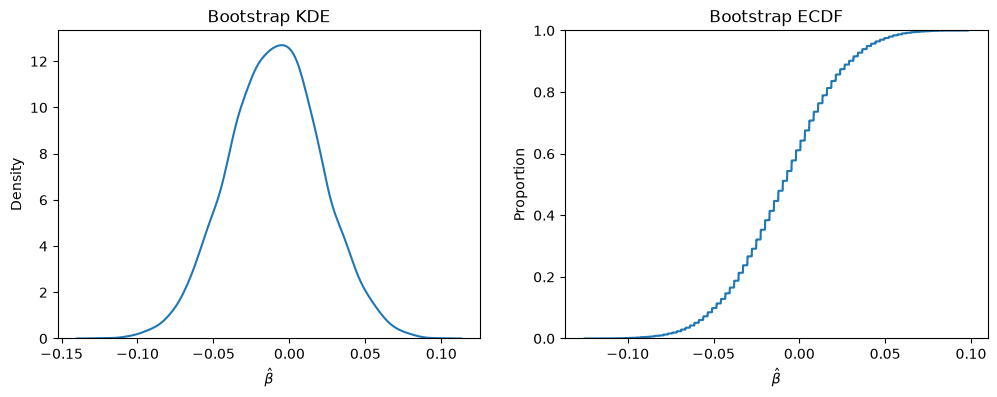

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


## 1.4

The KDE shows a bell shape of the ATE distribution. For this intervention, I'd say the range of values spans from around a difference of -0.10 to 0.80. I'm noticing that 0 is right in the middle of this span of differences.

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [18]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06106757  0.04176086]
95% CI: [-0.06887207  0.04959203]
99% CI: [-0.08941775  0.06760001]


## 1.5

For all three of these confidence intervals, we fail to reject the null hypothesis that the effect size is zero.. Zero is contained in all of these intervals, meaning that zero is a possible difference in the ATE. 

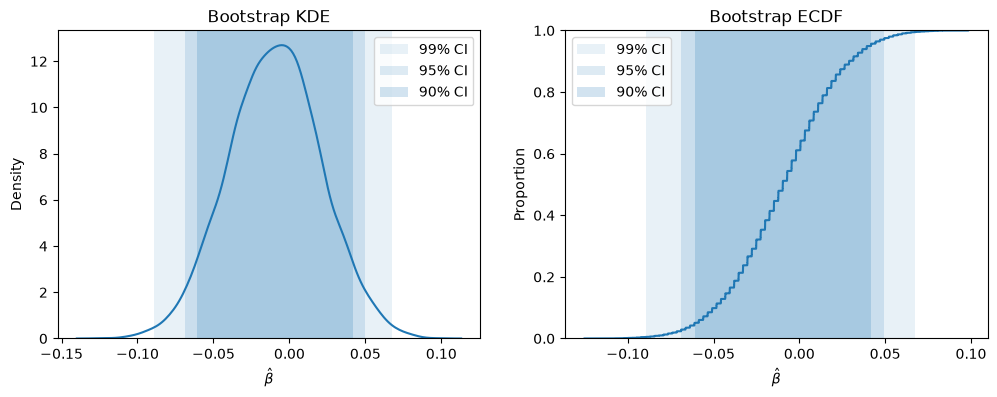

In [19]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**6.** What have we learned about inserting balloons into hearts?

## 1.6

We've technically learned nothing about inserting balloons into hearts, since no null hypothesis was rejected. Everything we've observed is something that was already assumed before testing. From our observations, we can conclude that inserting a balloon into your heart does not significantly improve one's chances of survival. 

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

In [26]:
betus = pd.read_csv('./data/diabetes.csv')
betus['outcome'] = (
    betus['outcome'].str.strip().str.lower().map({'success': 1, 'failure': 0})
)
betus.head(10)

,Unnamed: 0,treatment,outcome
0,1,met,1
1,2,rosi,0
2,3,rosi,1
3,4,lifestyle,1
4,5,met,1
5,6,lifestyle,1
6,7,lifestyle,1
7,8,rosi,1
8,9,rosi,1
9,10,met,0


In [27]:
# Cross Tabulation
print(pd.crosstab(betus['treatment'], betus['outcome']), '\n')

outcome      0    1
treatment          
lifestyle  109  125
met        120  112
rosi        90  143 



For the lifestyle group, the majority outcome is success. For the met group, the majority outcome is failure. For the Rosi group, the majority outcome is success. 

In [28]:
# Bootstrap
import numpy as np
import pandas as pd

R = 10000

a_df = betus.loc[betus['treatment'] == 'lifestyle', :]
b_df = betus.loc[betus['treatment'] == 'met', :]
c_df = betus.loc[betus['treatment'] == 'rosi', :]

a_outcome = []
b_outcome = []
c_outcome = []

ab_diff = []
ac_diff = []
bc_diff = []

for t in range(R):
  at_df = a_df.sample(frac=1.0, replace=True)
  bt_df = b_df.sample(frac=1.0, replace=True)
  ct_df = c_df.sample(frac=1.0, replace=True)

  a_mean = at_df['outcome'].mean()
  b_mean = bt_df['outcome'].mean()
  c_mean = ct_df['outcome'].mean()

  a_outcome.append(a_mean)
  b_outcome.append(b_mean)
  c_outcome.append(c_mean)

  ab_diff.append(a_mean - b_mean)
  ac_diff.append(a_mean - c_mean)
  bc_diff.append(b_mean - c_mean)
    

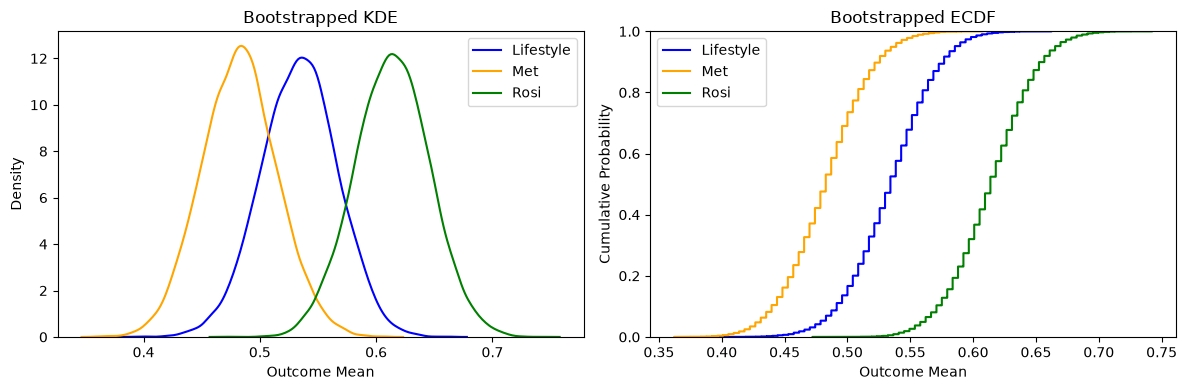

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Left subplot: Bootstrapped KDEs
sns.kdeplot(a_outcome, label='Lifestyle', color='blue', ax=ax[0])
sns.kdeplot(b_outcome, label='Met', color='orange', ax=ax[0])
sns.kdeplot(c_outcome, label='Rosi', color='green', ax=ax[0])
ax[0].set(
    title='Bootstrapped KDE', xlabel='Outcome Mean', ylabel='Density'
)
ax[0].legend()

# Right subplot: Bootstrapped ECDFs
sns.ecdfplot(a_outcome, label='Lifestyle', color='blue', ax=ax[1])
sns.ecdfplot(b_outcome, label='Met', color='orange', ax=ax[1])
sns.ecdfplot(c_outcome, label='Rosi', color='green', ax=ax[1])
ax[1].set(
    title='Bootstrapped ECDF',
    xlabel='Outcome Mean',
    ylabel='Cumulative Probability',
)
ax[1].legend()

plt.tight_layout()
plt.show()

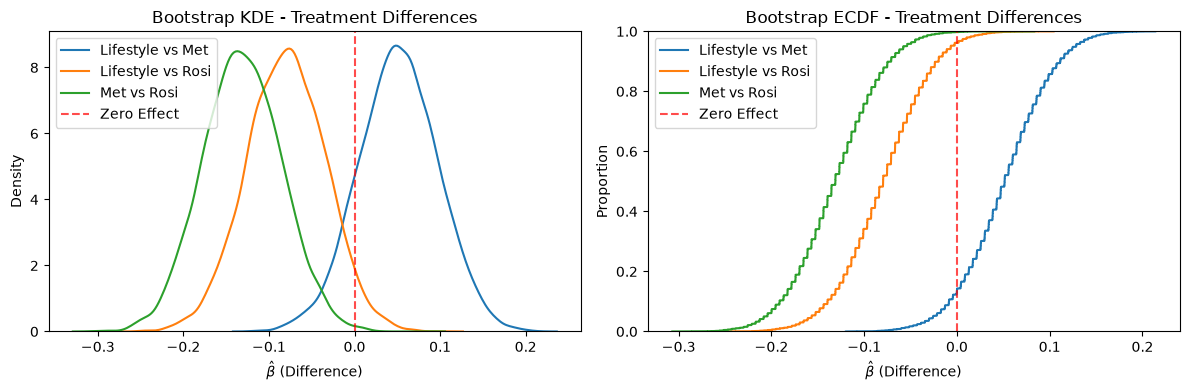

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(ab_diff, label="Lifestyle vs Met", ax=ax[0])
sns.kdeplot(ac_diff, label="Lifestyle vs Rosi", ax=ax[0])
sns.kdeplot(bc_diff, label="Met vs Rosi", ax=ax[0])
ax[0].axvline(
    0, color="red", linestyle="--", alpha=0.7, label="Zero Effect"
)
ax[0].set_xlabel(r"$\hat{\beta}$ (Difference)")
ax[0].set_title("Bootstrap KDE - Treatment Differences")
ax[0].legend()

sns.ecdfplot(ab_diff, label="Lifestyle vs Met", ax=ax[1])
sns.ecdfplot(ac_diff, label="Lifestyle vs Rosi", ax=ax[1])
sns.ecdfplot(bc_diff, label="Met vs Rosi", ax=ax[1])
ax[1].axvline(0, color="red", linestyle="--", alpha=0.7, label="Zero Effect")
ax[1].set_xlabel(r"$\hat{\beta}$ (Difference)")
ax[1].set_title("Bootstrap ECDF - Treatment Differences")
ax[1].legend()

plt.tight_layout()
plt.show()

In [32]:
ab90 = np.quantile(ab_diff, [.05, .95])
ab95 = np.quantile(ab_diff, [.025, .975])
ab99 = np.quantile(ab_diff, [.005, .995])
ac90 = np.quantile(ac_diff, [.05, .95])
ac95 = np.quantile(ac_diff, [.025, .975])
ac99 = np.quantile(ac_diff, [.005, .995])
bc90 = np.quantile(bc_diff, [.05, .95])
bc95 = np.quantile(bc_diff, [.025, .975])
bc99 = np.quantile(bc_diff, [.005, .995])

print(f"90% CI: {ab90}")
print(f"95% CI: {ab95}")
print(f"99% CI: {ab99}")
print(f"90% CI: {ac90}")
print(f"95% CI: {ac95}")
print(f"99% CI: {ac99}")
print(f"90% CI: {bc90}")
print(f"95% CI: {bc95}")
print(f"99% CI: {bc99}")

90% CI: [-0.02567971  0.12853669]
95% CI: [-0.03897915  0.14161509]
99% CI: [-0.07265049  0.1671828 ]
90% CI: [-0.15659734 -0.00663952]
95% CI: [-0.16958338  0.0102532 ]
99% CI: [-0.19955275  0.03622391]
90% CI: [-0.20821    -0.05769757]
95% CI: [-0.221123   -0.04069853]
99% CI: [-0.24730048 -0.01472538]


There are statistically significant differences shown by the confidence intervals above. At a 90% confidence level, there is a significant difference between the 'lifestyle' and 'rosi' treatments. At a 90%, 95%, and 99% confidence level, there is a significant difference between the 'met' and 'rosi' treatments. These statistically significant differences are identified by the confidence interval having no zero contained. 

## Report
### By: Aaron Witzel

In the United States, more than 1 in 3 adults are prediabetic. Among those with prediabetes, 1 in 4 will develop type 2 diabetes. Without any treatment, a pre-diabetic patient is far more likely to end up in that 25% of people quickly developing diabetes. This report analyzes a clinical trial done on pre-diabetics and considers 3 treatments used to reduce the progression to type 2 diabetes. These three treatments are: Metformin, Rosiglitazone, and lifestyle changes. The goal of this report is to provide an unbiased evaluation of each treatment's success in preventing diabetes. 

| Treatment | Failure | Success |
| :--- | :---: | :---: |
| **lifestyle** | 109 | 125 |
| **met** | 120 | 112 |
| **rosi** | 90 | 143 |

To start off our analysis, we performed cross-tabulation on the baseline data and got our point estimates. With the initial data, cross-tabulation gave the highest success probability to the treatment Rosiglitazone at 0.61. The next highest success probability was 0.53 with the treatment of lifestyle shifts. The lowest success probability was 0.48 with the Metformin treatment. Our first observations were that Rosiglitazone was significantly more successful in preventing diabetes development than the other two treatments, and that Metformin had a higher probability of failure than simple lifestyle changes. 

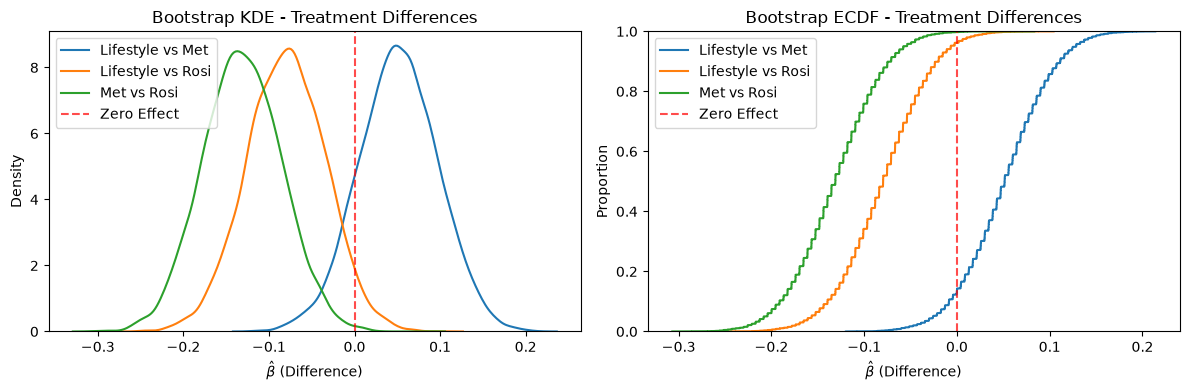

In order to test the validity of our point estimates, we used bootstrapping methods to further estimate the accuracy of our point estimate. After bootstrapping, we observed a consistently higher success rate among the patients who took the Rosiglitazone treatment than the next two treatments. At the 90% confidence level, confidence intervals further proved a significant difference between the Rosiglitazone and the other two individual treatments. We concluded a significantly higher success rate in preventing diabetes in pre-diabetic patients with Rosiglitazone over Metformin and lifestyle changes. 